# TP3 - Procesamiento del Lenguaje Natural (NLP)
**Inteligencia Artificial y Neurociencias**

**Leoni, Petra - Mendez, Agustín - Pizi, Lucía - Siles, Milagros**

## 2. Modelos clásicos de NLP

En esta parte se construye un baseline que combina una representación textual (TF-IDF) con un clasificador lineal, y luego se experimenta con variantes de preprocesamiento, entrada del modelo, features, clasificadores e hiperparámetros para intentar mejorarlo.

**Protocolo de evaluación** (definido en la parte 1):
- Se usan exactamente los conjuntos de `splits_tp3.csv` (split agrupado por propuesta, ≈70/15/15).

- Todas las decisiones se toman con validación (y con validación cruzada agrupada sobre train+val en la elección final). El conjunto de test se usa una única vez, al final (sección 2.8), para el baseline y el modelo elegido.
- Métrica principal: Macro-F1 respecto de `majority_label` (clases *favor*, *against*, *neutral*). Se reportan además accuracy, F1 por clase, tiempos de entrenamiento e inferencia.

**Estrategia de búsqueda:** las decisiones se toman de forma secuencial (*greedy*): primero el manejo del desbalance, luego el preprocesamiento, la entrada, las features y por último el clasificador y sus hiperparámetros. Cada paso parte de la mejor configuración del paso anterior. No es una búsqueda exhaustiva (algunas combinaciones no se prueban), pero mantiene el número de experimentos acotado y cada efecto es interpretable por separado.

### 2.0. Configuración

Se instalan e importan las dependencias.

In [1]:
!pip -q install datasets
!python -m spacy download es_core_news_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import os
import re
import time
import pickle
import platform
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

import nltk
import spacy
import sklearn
from nltk.corpus import stopwords
from sklearn.base import clone
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

nltk.download("stopwords", quiet=True)

SEED = 42
CLASES = ["favor", "against", "neutral"]   # mismo orden que en la parte 1
label2id = {c: i for i, c in enumerate(CLASES)}
id2label = {i: c for c, i in label2id.items()}
sns.set_theme(style="whitegrid")
np.random.seed(SEED)

# Hardware / versiones (para reportar costos)
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__, "| spaCy:", spacy.__version__)
print("CPU:", platform.processor() or platform.machine(), "| núcleos:", os.cpu_count())

Python: 3.13.16 | scikit-learn: 1.6.1 | spaCy: 3.8.18
CPU: x86_64 | núcleos: 2


### 2.1. Carga de datos y particiones

Construimos `df_modelado` igual que en la parte 1 (se descartan los 150 comentarios sin mayoría) y se le asigna a cada comentario su conjunto según `splits_tp3.csv`. Verificamos que todos los comentarios tengan conjunto asignado y que ninguna propuesta aparezca en más de un conjunto.

In [3]:
dataset = load_dataset("SINAI/ALIA-es-discriminative-stance-detection")
df = dataset["train"].to_pandas()

cols_anotadores = ["annotation_1", "annotation_2", "annotation_3"]
df_modelado = df[df["majority_label"].isin(CLASES)].copy().reset_index(drop=True)
df_modelado["label"] = df_modelado["majority_label"]
df_modelado["id"] = df_modelado["id"].astype(str)

# Nivel de acuerdo entre anotadores (se usa en el análisis de errores)
df_modelado["max_acuerdo"] = df_modelado[cols_anotadores].apply(lambda f: f.value_counts().max(), axis=1)
df_modelado["nivel_acuerdo"] = df_modelado["max_acuerdo"].map({3: "Total (3/3)", 2: "Parcial (2/3)"})

RUTA_SPLITS = "splits_tp3.csv"
if not os.path.exists(RUTA_SPLITS):
    try:
        from google.colab import files
        print("No se encontró splits_tp3.csv: subilo (lo genera la parte 1).")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Falta splits_tp3.csv (lo genera la parte 1).")

splits = pd.read_csv(RUTA_SPLITS, dtype={"id": str})
df_modelado = df_modelado.merge(splits, on="id", how="left", validate="one_to_one")
assert df_modelado["split"].notna().all(), "Hay comentarios sin split asignado"

train_df = df_modelado[df_modelado["split"] == "train"].reset_index(drop=True)
val_df = df_modelado[df_modelado["split"] == "val"].reset_index(drop=True)
test_df = df_modelado[df_modelado["split"] == "test"].reset_index(drop=True)

# Controles: todos los comentarios tienen split y no hay propuestas compartidas
assert len(train_df) + len(val_df) + len(test_df) == len(df_modelado) == 2850
print(f"Train: {len(train_df)} | Validación: {len(val_df)} | Test: {len(test_df)}")
for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert not set(a["target"]) & set(b["target"])

y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

display(pd.crosstab(df_modelado["split"], df_modelado["label"]).loc[["train", "val", "test"], CLASES])

README.md:   0%|          | 0.00/20.1k [00:00<?, ?B/s]

corpus_stance_detection_ALIA.jsonl:   0%|          | 0.00/4.48M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3000 [00:00<?, ? examples/s]

No se encontró splits_tp3.csv: subilo (lo genera la parte 1).


Saving splits_tp3.csv to splits_tp3.csv
Train: 2019 | Validación: 413 | Test: 418


label,favor,against,neutral
split,,,
train,1262,445,312
val,261,87,65
test,257,95,66


### 2.2. Preprocesamiento y herramientas de evaluación

Siguiendo el plan de la sección 1.7, se definen las variantes de preprocesamiento a comparar:

| Variante | Qué hace |
|---|---|
| `original` | Texto sin modificar (se respetan mayúsculas) |
| `minusculas` | Tokenización + minúsculas |
| `sin_acentos` | Minúsculas + eliminación de tildes |
| `sin_stopwords` | Minúsculas + eliminación de todas las stopwords de NLTK |
| `sin_stopwords_conserva_neg` | Igual, pero conservando las negaciones (*no*, *ni*, *sin*, *nunca*...) |
| `lemas` | Lematización con spaCy (`es_core_news_sm`) + minúsculas |
| `lemas_sin_stop_neg` | Lemas + eliminación de stopwords conservando negaciones |

Los textos preprocesados se calculan una sola vez y se guardan en caché. La lematización es el único paso con costo de cómputo apreciable, por lo que se mide su tiempo por separado.

In [4]:
stop_es = set(stopwords.words("spanish"))
NEGACIONES = {"no", "ni", "sin", "nunca", "tampoco", "nada", "nadie", "jamás",
              "ningún", "ninguna", "ninguno"}
stop_sin_neg = stop_es - NEGACIONES
print("Negaciones que estaban en la lista de stopwords:", sorted(NEGACIONES & stop_es))

RE_TOKEN = re.compile(r"\w+")
TOKEN_PATTERN = r"(?u)\b\w+\b"   # conserva tokens de 1 letra (p. ej. 'y', 'o')

def sin_acentos(t):
    return "".join(ch for ch in unicodedata.normalize("NFD", t) if unicodedata.category(ch) != "Mn")

nlp = spacy.load("es_core_news_sm", disable=["parser", "ner"])
_cache_lemas = {}

def lematizar(textos):
    pendientes = [t for t in pd.unique(pd.Series(textos)) if t not in _cache_lemas]
    for t, doc in zip(pendientes, nlp.pipe(pendientes, batch_size=64)):
        _cache_lemas[t] = [tok.lemma_.lower() for tok in doc if not (tok.is_space or tok.is_punct)]
    return [_cache_lemas[t] for t in textos]

VARIANTES = {
    "original":                   dict(minus=False, acentos=True,  lemas=False, stop=None),
    "minusculas":                 dict(minus=True,  acentos=True,  lemas=False, stop=None),
    "sin_acentos":                dict(minus=True,  acentos=False, lemas=False, stop=None),
    "sin_stopwords":              dict(minus=True,  acentos=True,  lemas=False, stop=stop_es),
    "sin_stopwords_conserva_neg": dict(minus=True,  acentos=True,  lemas=False, stop=stop_sin_neg),
    "lemas":                      dict(minus=True,  acentos=True,  lemas=True,  stop=None),
    "lemas_sin_stop_neg":         dict(minus=True,  acentos=True,  lemas=True,  stop=stop_sin_neg),
}

def preprocesar(textos, variante):
    cfg = VARIANTES[variante]
    textos = list(textos)
    if variante == "original":
        return textos
    if cfg["lemas"]:
        toks = lematizar(textos)
    else:
        toks = [RE_TOKEN.findall(t.lower() if cfg["minus"] else t) for t in textos]
    if cfg["stop"] is not None:
        toks = [[w for w in ts if w not in cfg["stop"]] for ts in toks]
    if not cfg["acentos"]:
        toks = [[sin_acentos(w) for w in ts] for ts in toks]
    return [" ".join(ts) for ts in toks]

# Ejemplo
ejemplo = train_df["comment"].iloc[3]
print("ORIGINAL:", ejemplo[:200], "\n")
for v in ["sin_stopwords", "sin_stopwords_conserva_neg", "lemas_sin_stop_neg"]:
    print(f"{v}:", preprocesar([ejemplo], v)[0][:200], "\n")

Negaciones que estaban en la lista de stopwords: ['nada', 'ni', 'no', 'sin']
ORIGINAL: Siempre que esa bajada de ingresos sea a costa de subir el impuesto a los vehículos a motor contaminante. 

sin_stopwords: siempre bajada ingresos costa subir impuesto vehículos motor contaminante 

sin_stopwords_conserva_neg: siempre bajada ingresos costa subir impuesto vehículos motor contaminante 

lemas_sin_stop_neg: siempre bajada ingreso ser costa subir impuesto vehículo motor contaminante 



In [5]:
# Costo de la lematización: se lematizan una vez todos los comentarios y títulos de propuesta
todos = pd.concat([df_modelado["comment"], df_modelado["target"]]).unique().tolist()
_cache_lemas.clear()
t0 = time.perf_counter()
lematizar(todos)
T_LEMATIZACION = time.perf_counter() - t0
print(f"Lematización de {len(todos)} textos únicos: {T_LEMATIZACION:.1f} s "
      f"({T_LEMATIZACION / len(todos) * 1000:.1f} ms por texto)")

Lematización de 3223 textos únicos: 10.7 s (3.3 ms por texto)


**Entrada del modelo.** Como vimos en la parte 1, la postura depende de la propuesta (el mismo texto puede ser *favor* en una propuesta y *against* en otra). Se comparan tres formas de armar la entrada:
- `comentario`: solo el comentario.

- `concatenado`: título de la propuesta + comentario en un mismo texto (comparten vocabulario).
- `separado`: un vectorizador para el título y otro para el comentario (features independientes).

No se usa la `description` completa porque es muy larga (mediana de 105 palabras) y es casi siempre la misma dentro de una propuesta: en bolsa de palabras aportaría sobre todo vocabulario temático.

A continuación se definen las funciones que arman la entrada, construyen el pipeline (vectorizador + clasificador), y entrenan, evalúan y registran cada experimento.

In [6]:
DFS = {"train": train_df, "val": val_df, "test": test_df}
_cache_prep = {}

def textos(split, campo, variante):
    clave = (split, campo, variante)
    if clave not in _cache_prep:
        _cache_prep[clave] = preprocesar(DFS[split][campo], variante)
    return _cache_prep[clave]

def armar_X(split, variante, entrada):
    com = textos(split, "comment", variante)
    if entrada == "comentario":
        return com
    prop = textos(split, "target", variante)
    if entrada == "concatenado":
        return [p + " " + c for p, c in zip(prop, com)]
    if entrada == "separado":
        return pd.DataFrame({"prop": prop, "com": com})
    raise ValueError(entrada)

def unir(a, b):
    return pd.concat([a, b], ignore_index=True) if isinstance(a, pd.DataFrame) else list(a) + list(b)

def tomar(X, idx):
    return X.iloc[idx] if isinstance(X, pd.DataFrame) else [X[i] for i in idx]

def vectorizador(cfg_feat):
    cfg = dict(cfg_feat)
    tipo = cfg.pop("tipo")
    if tipo == "bow":
        return CountVectorizer(token_pattern=TOKEN_PATTERN, lowercase=False, **cfg)
    if tipo == "tfidf":
        return TfidfVectorizer(token_pattern=TOKEN_PATTERN, lowercase=False, **cfg)
    if tipo == "char":
        return TfidfVectorizer(analyzer="char_wb", lowercase=False, **cfg)
    if tipo == "word+char":
        return FeatureUnion([
            ("word", TfidfVectorizer(token_pattern=TOKEN_PATTERN, lowercase=False,
                                     ngram_range=(1, 2), sublinear_tf=True, min_df=2)),
            ("char", TfidfVectorizer(analyzer="char_wb", lowercase=False,
                                     ngram_range=(2, 5), sublinear_tf=True, min_df=2)),
        ])
    raise ValueError(tipo)

def armar_pipeline(config):
    if config["entrada"] == "separado":
        feats = ColumnTransformer([("prop", vectorizador(config["cfg_feat"]), "prop"),
                                   ("com", vectorizador(config["cfg_feat"]), "com")])
    else:
        feats = vectorizador(config["cfg_feat"])
    return Pipeline([("feats", feats), ("clf", clone(config["modelo"]))])

def metricas(y_true, y_pred):
    f1s = f1_score(y_true, y_pred, labels=CLASES, average=None, zero_division=0)
    return {"macro_f1": f1_score(y_true, y_pred, labels=CLASES, average="macro", zero_division=0),
            "accuracy": accuracy_score(y_true, y_pred),
            **{f"f1_{c}": f for c, f in zip(CLASES, f1s)}}

resultados = []   # registro de todos los experimentos sobre validación

def experimento(grupo, nombre, variante, entrada, cfg_feat, modelo):
    config = dict(variante=variante, entrada=entrada, cfg_feat=cfg_feat, modelo=clone(modelo))
    X_tr, X_va = armar_X("train", variante, entrada), armar_X("val", variante, entrada)
    pipe = armar_pipeline(config)
    t0 = time.perf_counter(); pipe.fit(X_tr, y_train); t_train = time.perf_counter() - t0
    t0 = time.perf_counter(); y_pred = pipe.predict(X_va); t_inf = time.perf_counter() - t0
    try:
        n_feats = len(pipe.named_steps["feats"].get_feature_names_out())
    except Exception:
        n_feats = np.nan
    fila = {"grupo": grupo, "experimento": nombre, **metricas(y_val, y_pred),
            "t_train_s": t_train, "t_inf_val_s": t_inf, "n_features": n_feats, "config": config}
    resultados.append(fila)
    return fila

def tabla(grupo):
    t = pd.DataFrame([r for r in resultados if r["grupo"] == grupo]).drop(columns=["grupo", "config"])
    return (t.sort_values("macro_f1", ascending=False).set_index("experimento")
             .style.format({c: "{:.3f}" for c in ["macro_f1", "accuracy"] + [f"f1_{x}" for x in CLASES]}
                           | {"t_train_s": "{:.2f}", "t_inf_val_s": "{:.3f}", "n_features": "{:,.0f}"})
             .background_gradient(subset=["macro_f1"], cmap="Greens"))

def mejor(grupo):
    return max((r for r in resultados if r["grupo"] == grupo), key=lambda r: r["macro_f1"])

### 2.3. Baseline

**Baseline:** TF-IDF de unigramas sobre el comentario en minúsculas (equivalente al `TfidfVectorizer` por defecto) + Regresión Logística sin ajustes. Como referencia mínima se incluyen dos clasificadores triviales: uno que siempre predice la clase mayoritaria (*favor*) y uno que predice al azar respetando las proporciones de clase.

In [7]:
CFG_UNIGRAMAS = {"tipo": "tfidf", "ngram_range": (1, 1)}

experimento("referencia", "Dummy: clase mayoritaria", "minusculas", "comentario", CFG_UNIGRAMAS,
            DummyClassifier(strategy="most_frequent"))
experimento("referencia", "Dummy: aleatorio estratificado", "minusculas", "comentario", CFG_UNIGRAMAS,
            DummyClassifier(strategy="stratified", random_state=SEED))
BASELINE = experimento("referencia", "Baseline: TF-IDF unigramas + LogReg", "minusculas", "comentario",
                       CFG_UNIGRAMAS, LogisticRegression(max_iter=2000, random_state=SEED))
tabla("referencia")

,macro_f1,accuracy,f1_favor,f1_against,f1_neutral,t_train_s,t_inf_val_s,n_features
experimento,,,,,,,,
Dummy: aleatorio estratificado,0.331,0.458,0.617,0.211,0.165,0.11,0.016,"12,364"
Baseline: TF-IDF unigramas + LogReg,0.329,0.649,0.784,0.143,0.060,0.85,0.031,"12,364"
Dummy: clase mayoritaria,0.258,0.632,0.774,0.000,0.000,0.11,0.016,"12,364"


**Observaciones**

- El baseline obtiene un Macro-F1 de **0,329** en validación, prácticamente igual al de un clasificador que predice al azar respetando las proporciones (0,331) y apenas por encima del que predice siempre *favor* (0,258).

- Su accuracy (0,649) es la más alta de los tres, pero solo porque se parece al clasificador mayoritario: el F1 de *against* es 0,143 y el de *neutral* 0,060, es decir que casi siempre predice *favor*. Esto muestra por qué la accuracy no sirve como métrica principal en este problema: el Dummy mayoritario tiene accuracy 0,632 sin haber aprendido nada.

### 2.4. Desbalance de clases

*favor* representa ≈62% de los datos. Se compara la regresión logística sin pesos contra `class_weight="balanced"`, que pondera cada clase en forma inversamente proporcional a su frecuencia, de modo que equivocarse en *neutral* "cuesta" más que equivocarse en *favor*.

In [8]:
experimento("desbalance", "Sin pesos (baseline)", "minusculas", "comentario", CFG_UNIGRAMAS,
            LogisticRegression(max_iter=2000, random_state=SEED))
experimento("desbalance", "class_weight='balanced'", "minusculas", "comentario", CFG_UNIGRAMAS,
            LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))
tabla("desbalance")

,macro_f1,accuracy,f1_favor,f1_against,f1_neutral,t_train_s,t_inf_val_s,n_features
experimento,,,,,,,,
class_weight='balanced',0.478,0.581,0.714,0.427,0.292,0.60,0.033,"12,364"
Sin pesos (baseline),0.329,0.649,0.784,0.143,0.060,0.85,0.066,"12,364"


In [9]:
LR_BAL = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)

**Observaciones**

- Balancear las clases es, con diferencia, el cambio que más mejora el resultado: el Macro-F1 pasa de **0,329 a 0,478** (+15 puntos). El F1 de *against* sube de 0,14 a 0,43 y el de *neutral* de 0,06 a 0,29.

- Como contrapartida, la accuracy baja de 0,649 a 0,581 y el F1 de *favor* de 0,78 a 0,71: el modelo deja de "apostar" a la clase mayoritaria y empieza a predecir las minoritarias, con más errores sobre *favor*.
- A partir de acá todos los experimentos con regresión logística usan `class_weight="balanced"` (`LR_BAL`).

### 2.5. Variantes de preprocesamiento

Se comparan las variantes definidas en 2.2, con TF-IDF de unigramas y de uni+bigramas (las negaciones y expresiones como *"no estoy de acuerdo"* dependen del orden de las palabras, así que el efecto de eliminar stopwords puede cambiar al usar bigramas).

In [10]:
CFG_BIGRAMAS = {"tipo": "tfidf", "ngram_range": (1, 2)}

for variante in VARIANTES:
    for nombre_ng, cfg in [("1-gramas", CFG_UNIGRAMAS), ("1-2-gramas", CFG_BIGRAMAS)]:
        experimento("preprocesamiento", f"{variante} | {nombre_ng}", variante, "comentario", cfg, LR_BAL)

tabla("preprocesamiento")

,macro_f1,accuracy,f1_favor,f1_against,f1_neutral,t_train_s,t_inf_val_s,n_features
experimento,,,,,,,,
minusculas | 1-gramas,0.478,0.581,0.714,0.427,0.292,1.24,0.031,"12,364"
sin_stopwords_conserva_neg | 1-gramas,0.469,0.586,0.717,0.400,0.290,0.67,0.037,"12,142"
lemas_sin_stop_neg | 1-2-gramas,0.468,0.608,0.737,0.400,0.267,1.11,0.032,"53,524"
sin_stopwords | 1-gramas,0.464,0.586,0.719,0.398,0.274,0.46,0.037,"12,138"
sin_acentos | 1-gramas,0.462,0.571,0.706,0.439,0.242,0.63,0.041,"11,919"
lemas | 1-gramas,0.459,0.571,0.703,0.441,0.234,1.12,0.033,"8,911"
lemas | 1-2-gramas,0.459,0.593,0.720,0.429,0.229,2.31,0.091,"57,209"
sin_stopwords_conserva_neg | 1-2-gramas,0.458,0.608,0.738,0.419,0.218,4.24,0.068,"59,356"
lemas_sin_stop_neg | 1-gramas,0.455,0.559,0.690,0.407,0.269,0.54,0.020,"8,834"


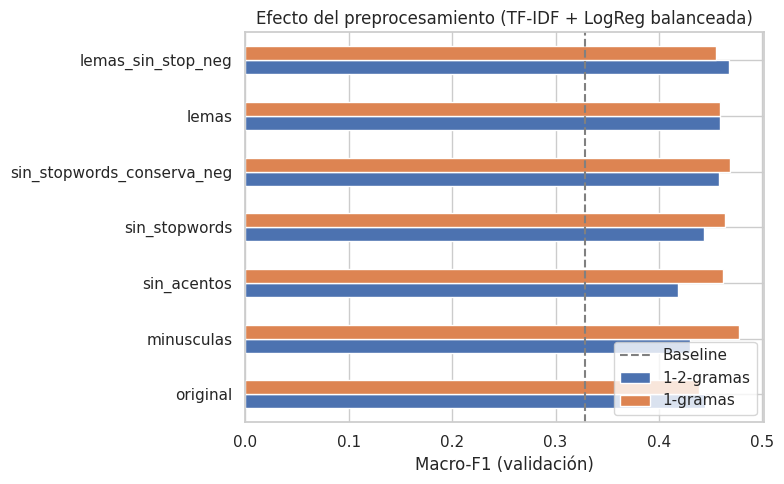

Mejor preprocesamiento: minusculas | 1-gramas → Macro-F1 = 0.478


In [11]:
# Vista resumida: Macro-F1 por variante y n-gramas
pp = pd.DataFrame([r for r in resultados if r["grupo"] == "preprocesamiento"])
pp[["variante", "ngramas"]] = pp["experimento"].str.split(" | ", regex=False, expand=True)
piv = pp.pivot(index="variante", columns="ngramas", values="macro_f1").loc[list(VARIANTES)]

ax = piv.plot.barh(figsize=(8, 5))
ax.axvline(BASELINE["macro_f1"], ls="--", c="gray", label="Baseline")
ax.set_xlabel("Macro-F1 (validación)"); ax.set_ylabel("")
ax.set_title("Efecto del preprocesamiento (TF-IDF + LogReg balanceada)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

MEJOR_PREP = mejor("preprocesamiento")
VARIANTE = MEJOR_PREP["config"]["variante"]
print("Mejor preprocesamiento:", MEJOR_PREP["experimento"], f"→ Macro-F1 = {MEJOR_PREP['macro_f1']:.3f}")

**Observaciones**

- Ninguna variante supera al preprocesamiento mínimo (minúsculas + unigramas, Macro-F1 = 0,478). Todas las variantes quedan entre 0,42 y 0,48, y las diferencias entre las mejores son de 1–2 puntos, del orden del ruido esperable con 65 comentarios *neutral* en validación.

- Eliminar las Stopwords no ayuda. Conservar las negaciones es levemente mejor que eliminarlas todas (0,469 vs. 0,464 con unigramas; 0,458 vs. 0,444 con bigramas), en la dirección esperada según la parte 1, pero la diferencia es chica.
- La lematización no mejora (0,459 con unigramas) y es el único paso con costo apreciable (≈3,3 ms por texto, 10,7 s para todo el corpus). No se justifica.
- Respetar mayúsculas (`original`, 0,439) o quitar acentos (`sin_acentos`, 0,462) es algo peor que pasar a minúsculas.
- Los bigramas empeoran el resultado en casi todas las variantes (por ejemplo 0,478 → 0,430 en `minusculas`), salvo en las lematizadas sin stopwords. Una explicación posible es que, con solo ≈2.000 comentarios, la mayoría de los bigramas aparece una sola vez: el vocabulario se multiplica por 5 (de 12k a 70k features) sin aportar señal. Vale aclarar que esta comparación se hizo con `C=1` fijo. Con 5 veces más features, el `C` óptimo probablemente sea otro, así que parte de la desventaja de los bigramas puede deberse a no haber reajustado la regularización (ver limitaciones en 2.12).

### 2.6. Entrada del modelo: comentario vs. propuesta + comentario

Con el mejor preprocesamiento y n-gramas del paso anterior, se comparan las tres formas de armar la entrada descriptas en 2.2.

In [12]:
CFG_FEAT = MEJOR_PREP["config"]["cfg_feat"]
for entrada in ["comentario", "concatenado", "separado"]:
    experimento("entrada", entrada, VARIANTE, entrada, CFG_FEAT, LR_BAL)

MEJOR_ENTRADA = mejor("entrada")
ENTRADA = MEJOR_ENTRADA["config"]["entrada"]
print("Mejor entrada:", ENTRADA)
tabla("entrada")

Mejor entrada: comentario


,macro_f1,accuracy,f1_favor,f1_against,f1_neutral,t_train_s,t_inf_val_s,n_features
experimento,,,,,,,,
comentario,0.478,0.581,0.714,0.427,0.292,0.81,0.067,"12,364"
concatenado,0.460,0.567,0.706,0.422,0.254,0.40,0.050,"12,447"
separado,0.418,0.571,0.710,0.441,0.102,0.68,0.068,"13,148"


**Observaciones**

- Agregar la propuesta empeora el resultado: solo comentario 0,478, concatenado 0,460, por separado 0,418. Con la entrada separada el F1 de *neutral* cae a 0,10.
- Es lo esperable con un split agrupado: las propuestas de validación nunca se vieron en train, así que las features del título solo aportan vocabulario temático que no generaliza. Por otro lado, un modelo de bolsa de palabras no puede representar la *relación* entre el comentario y la propuesta (que es lo que define la postura): solo suma las features de ambos.

- Es una limitación estructural de los enfoques clásicos, que los encoders (parte 3) y los LLMs (parte 4) sí pueden abordar al procesar ambos textos juntos.

### 2.7. Representación textual (features)

Se comparan distintas representaciones manteniendo el preprocesamiento y la entrada elegidos:
- **Bag-of-Words** (conteos) y **BoW binario** (presencia/ausencia).

- **TF-IDF** con unigramas, uni+bigramas y uni+bi+trigramas.
- **TF-IDF con `sublinear_tf` y `min_df=2`**: atenúa palabras muy repetidas en un mismo comentario y descarta términos que aparecen una sola vez (ruido, errores de tipeo).
- **N-gramas de caracteres** (`char_wb`, 2 a 5): robustos a errores ortográficos y variaciones morfológicas, una alternativa barata a la lematización.
- **Palabras + caracteres** combinados.

In [13]:
CONFIGS_FEATURES = {
    "BoW 1-2":                         {"tipo": "bow", "ngram_range": (1, 2)},
    "BoW binario 1-2":                 {"tipo": "bow", "ngram_range": (1, 2), "binary": True},
    "TF-IDF 1":                        {"tipo": "tfidf", "ngram_range": (1, 1)},
    "TF-IDF 1-2":                      {"tipo": "tfidf", "ngram_range": (1, 2)},
    "TF-IDF 1-3":                      {"tipo": "tfidf", "ngram_range": (1, 3)},
    "TF-IDF 1-2 sublinear min_df=2":   {"tipo": "tfidf", "ngram_range": (1, 2), "sublinear_tf": True, "min_df": 2},
    "TF-IDF 1-3 sublinear min_df=2":   {"tipo": "tfidf", "ngram_range": (1, 3), "sublinear_tf": True, "min_df": 2},
    "Char 2-5 (char_wb)":              {"tipo": "char", "ngram_range": (2, 5), "sublinear_tf": True, "min_df": 2},
    "Char 3-6 (char_wb)":              {"tipo": "char", "ngram_range": (3, 6), "sublinear_tf": True, "min_df": 2},
    "Palabras 1-2 + char 2-5":         {"tipo": "word+char"},
}
for nombre, cfg in CONFIGS_FEATURES.items():
    experimento("features", nombre, VARIANTE, ENTRADA, cfg, LR_BAL)

MEJOR_FEAT = mejor("features")
CFG_FEAT = MEJOR_FEAT["config"]["cfg_feat"]
print("Mejores features:", MEJOR_FEAT["experimento"])
tabla("features")

Mejores features: Char 2-5 (char_wb)


,macro_f1,accuracy,f1_favor,f1_against,f1_neutral,t_train_s,t_inf_val_s,n_features
experimento,,,,,,,,
Char 2-5 (char_wb),0.493,0.574,0.691,0.474,0.313,2.77,0.248,"29,061"
Char 3-6 (char_wb),0.488,0.581,0.704,0.473,0.286,2.81,0.239,"44,579"
TF-IDF 1,0.478,0.581,0.714,0.427,0.292,0.65,0.068,"12,364"
Palabras 1-2 + char 2-5,0.459,0.581,0.710,0.457,0.210,4.34,0.421,"45,764"
TF-IDF 1-3 sublinear min_df=2,0.439,0.581,0.720,0.377,0.220,0.96,0.134,"23,479"
TF-IDF 1-2 sublinear min_df=2,0.433,0.564,0.701,0.389,0.209,0.51,0.060,"16,703"
TF-IDF 1-3,0.431,0.610,0.739,0.423,0.130,5.37,0.131,"161,104"
TF-IDF 1-2,0.430,0.586,0.718,0.396,0.178,1.51,0.112,"69,942"
BoW binario 1-2,0.420,0.620,0.758,0.331,0.172,3.24,0.102,"69,942"


**Observaciones**

- La mejor representación son los n-gramas de caracteres (`char_wb` 2–5, Macro-F1 = **0,493**; 3–6 obtiene 0,488), algo por encima de TF-IDF de unigramas de palabras (0,478). Los n-gramas de caracteres capturan raíces y variantes ortográficas (*acuerd-*, *apoy-*, *totalm-*) sin lematizar, y son robustos a errores de tipeo, frecuentes en estos comentarios. La mejora es de 1,5 puntos, dentro del margen de ruido.
- TF-IDF supera a BoW con las mismas features (1-2-gramas: 0,430 vs. 0,401 con conteos y 0,420 binario).

- Igual que en 2.5, sumar n-gramas de palabras más largos no ayuda: los trigramas llevan el vocabulario a 161k features (y el entrenamiento a 5,4 s) sin mejorar. `sublinear_tf` + `min_df=2` reduce mucho la dimensionalidad (de 70k a 17k) con un resultado equivalente.
- Combinar palabras y caracteres (0,459) es peor que usar solo caracteres, probablemente por los bigramas de palabras incluidos en la combinación.

### 2.8. Clasificadores e hiperparámetros

Con la representación elegida se comparan cuatro clasificadores vistos en TD VI, buscando sus hiperparámetros principales sobre validación:

| Modelo | Hiperparámetros explorados | Desbalance |
|---|---|---|
| Regresión Logística | `C` (inverso de la regularización) | `class_weight="balanced"` |
| SVM lineal (`LinearSVC`) | `C` | `class_weight="balanced"` |
| Naive Bayes complementario | `alpha` (suavizado); con TF-IDF y con conteos (BoW), que es su representación "natural" | Complement NB está pensado para clases desbalanceadas |
| Random Forest | `min_samples_leaf`, `max_features` | `class_weight="balanced_subsample"` |

In [14]:
CFG_BOW_NB = {"tipo": "bow", "ngram_range": (1, 2)}

grilla = []
for C in [0.1, 0.3, 1, 3, 10, 30]:
    grilla.append((f"LogReg C={C}", CFG_FEAT,
                   LogisticRegression(C=C, max_iter=5000, class_weight="balanced", random_state=SEED)))
for C in [0.01, 0.03, 0.1, 0.3, 1, 3]:
    grilla.append((f"LinearSVC C={C}", CFG_FEAT,
                   LinearSVC(C=C, max_iter=10000, class_weight="balanced", random_state=SEED)))
for alpha in [0.03, 0.1, 0.3, 1.0]:
    grilla.append((f"ComplementNB alpha={alpha} | features elegidas", CFG_FEAT, ComplementNB(alpha=alpha)))
    grilla.append((f"ComplementNB alpha={alpha} | BoW 1-2", CFG_BOW_NB, ComplementNB(alpha=alpha)))
for leaf in [1, 3]:
    for mf in ["sqrt", "log2"]:
        grilla.append((f"RandomForest leaf={leaf} max_features={mf}", CFG_FEAT,
                       RandomForestClassifier(n_estimators=500, min_samples_leaf=leaf, max_features=mf,
                                              class_weight="balanced_subsample", n_jobs=-1,
                                              random_state=SEED)))

for nombre, cfg, modelo in grilla:
    experimento("modelos", nombre, VARIANTE, ENTRADA, cfg, modelo)

tabla("modelos")

,macro_f1,accuracy,f1_favor,f1_against,f1_neutral,t_train_s,t_inf_val_s,n_features
experimento,,,,,,,,
LogReg C=1,0.493,0.574,0.691,0.474,0.313,2.97,0.229,"29,061"
LogReg C=10,0.492,0.600,0.720,0.470,0.288,3.80,0.251,"29,061"
LogReg C=3,0.491,0.596,0.717,0.469,0.288,5.83,0.368,"29,061"
LogReg C=30,0.482,0.598,0.721,0.444,0.279,5.68,0.292,"29,061"
LogReg C=0.3,0.474,0.545,0.660,0.473,0.289,2.13,0.265,"29,061"
LogReg C=0.1,0.467,0.523,0.632,0.459,0.309,1.49,0.235,"29,061"
ComplementNB alpha=0.03 | features elegidas,0.463,0.584,0.720,0.391,0.279,1.03,0.174,"29,061"
ComplementNB alpha=0.1 | features elegidas,0.455,0.593,0.727,0.358,0.281,1.09,0.304,"29,061"
LinearSVC C=1,0.450,0.593,0.727,0.382,0.241,1.40,0.183,"29,061"


,macro_f1,accuracy,f1_favor,f1_against,f1_neutral,t_train_s
experimento,,,,,,
LogReg C=1,0.493,0.574,0.691,0.474,0.313,2.974
ComplementNB alpha=0.03 | features elegidas,0.463,0.584,0.720,0.391,0.279,1.035
LinearSVC C=1,0.450,0.593,0.727,0.382,0.241,1.398
RandomForest leaf=3 max_features=log2,0.386,0.632,0.764,0.243,0.150,3.989


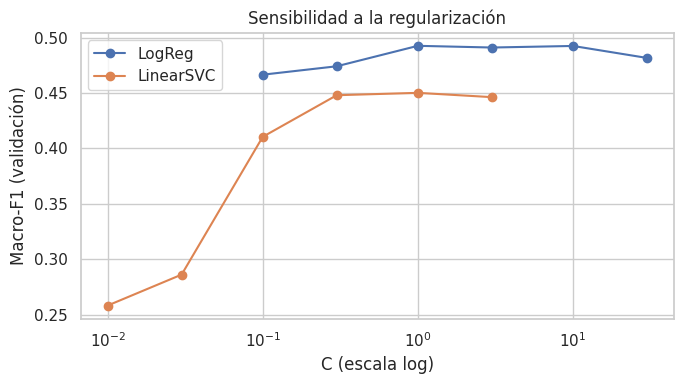

In [15]:
# Mejor configuración de cada tipo de modelo
mod = pd.DataFrame([r for r in resultados if r["grupo"] == "modelos"])
mod["tipo_modelo"] = mod["experimento"].str.split().str[0]
mejores_por_modelo = mod.loc[mod.groupby("tipo_modelo")["macro_f1"].idxmax()].sort_values("macro_f1", ascending=False)
display(mejores_por_modelo[["experimento", "macro_f1", "accuracy"] + [f"f1_{c}" for c in CLASES] + ["t_train_s"]]
        .round(3).set_index("experimento"))

# Sensibilidad a C en los modelos lineales
fig, ax = plt.subplots(figsize=(7, 4))
for tipo in ["LogReg", "LinearSVC"]:
    s = mod[mod["tipo_modelo"] == tipo].copy()
    s["C"] = s["experimento"].str.extract(r"C=([\d.]+)").astype(float)
    ax.plot(s["C"], s["macro_f1"], marker="o", label=tipo)
ax.set_xscale("log"); ax.set_xlabel("C (escala log)"); ax.set_ylabel("Macro-F1 (validación)")
ax.set_title("Sensibilidad a la regularización"); ax.legend(); plt.tight_layout(); plt.show()

#### 2.8.1. Estabilidad de la selección: validación cruzada agrupada

El conjunto de validación tiene solo ≈15% de los datos (unos 60 comentarios *neutral*), así que elegir el modelo por una única partición es ruidoso. Para la elección final, la mejor configuración de cada tipo de modelo se evalúa además con validación cruzada de 5 folds agrupada por propuesta (`StratifiedGroupKFold`) sobre train + validación. El test no se usa.

**Criterio de selección:** se elige la configuración con mayor Macro-F1 promedio en esta validación cruzada.

In [16]:
X_cache_trval = {}

def cv_agrupada(config, n_splits=5):
    clave = (config["variante"], config["entrada"])
    if clave not in X_cache_trval:
        X_cache_trval[clave] = unir(armar_X("train", *clave), armar_X("val", *clave))
    X = X_cache_trval[clave]
    y = np.concatenate([y_train, y_val])
    grupos = np.concatenate([train_df["target"], val_df["target"]])
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    scores = []
    for idx_tr, idx_te in sgkf.split(np.zeros(len(y)), y, groups=grupos):
        pipe = armar_pipeline(config).fit(tomar(X, idx_tr), y[idx_tr])
        scores.append(f1_score(y[idx_te], pipe.predict(tomar(X, idx_te)), average="macro"))
    return np.array(scores)

candidatos = [r for r in resultados if r["experimento"] in set(mejores_por_modelo["experimento"])
              and r["grupo"] == "modelos"]
# Se agrega también la LogReg balanceada con features por defecto (punto de partida) como referencia
candidatos.append(next(r for r in resultados if r["grupo"] == "desbalance" and "balanced" in r["experimento"]))

filas_cv = []
for r in candidatos:
    s = cv_agrupada(r["config"])
    filas_cv.append({"experimento": r["experimento"], "macro_f1_val": r["macro_f1"],
                     "macro_f1_cv_media": s.mean(), "macro_f1_cv_std": s.std()})
cv_df = pd.DataFrame(filas_cv).sort_values("macro_f1_cv_media", ascending=False).set_index("experimento")
display(cv_df.round(3))

ELEGIDO = next(r for r in candidatos if r["experimento"] == cv_df.index[0])
print("Configuración elegida:", ELEGIDO["experimento"])
print({k: v for k, v in ELEGIDO["config"].items()})

,macro_f1_val,macro_f1_cv_media,macro_f1_cv_std
experimento,,,
LogReg C=1,0.493,0.456,0.030
ComplementNB alpha=0.03 | features elegidas,0.463,0.442,0.038
class_weight='balanced',0.478,0.442,0.039
LinearSVC C=1,0.450,0.439,0.019
RandomForest leaf=3 max_features=log2,0.386,0.360,0.029


Configuración elegida: LogReg C=1
{'variante': 'minusculas', 'entrada': 'comentario', 'cfg_feat': {'tipo': 'char', 'ngram_range': (2, 5), 'sublinear_tf': True, 'min_df': 2}, 'modelo': LogisticRegression(C=1, class_weight='balanced', max_iter=5000, random_state=42)}


**Observaciones**

- Regresión logística es el mejor clasificador, tanto en validación (0,493) como en validación cruzada (**0,456 ± 0,030**), y es poco sensible a `C` entre 1 y 10 (0,491–0,493).
- Complement NB (0,442 ± 0,038) y SVM lineal (0,439 ± 0,019) quedan cerca. Las diferencias entre los cuatro mejores candidatos (incluida la LogReg con unigramas de palabras, 0,442) son menores que un desvío estándar entre folds: no hay un ganador claro y cualquiera de los modelos lineales es una opción razonable.

- Naive Bayes es muy sensible al suavizado: con `alpha=1` (el valor por defecto) predice siempre *favor* (Macro-F1 = 0,258), y solo funciona con `alpha` chico.
- SVM lineal con `C` chico (0,01–0,03) también colapsa a la clase mayoritaria.
- Random Forest es claramente el peor (0,360 en CV) y además el más lento (hasta 24 s): incluso con `class_weight="balanced_subsample"` predice casi siempre *favor* (F1 de *against* = 0,02 en varias configuraciones). En representaciones de texto muy dispersas y de alta dimensión, cada árbol ve un subconjunto chico de features, la mayoría irrelevantes, y con hojas puras los pesos de clase casi no cambian las predicciones.
- El Macro-F1 promedio en CV (0,456) es 3,7 puntos menor que en validación (0,493). Es esperable: la configuración se eligió como la mejor entre ≈60 probadas sobre esa misma validación, así que su puntaje en validación está inflado (sesgo de selección). La CV es una estimación más honesta.
- Limitación: los hiperparámetros de NB y RF se exploraron sobre features elegidas con regresión logística, que podrían no ser óptimas para ellos.

### 2.9. Evaluación final en test

Recién ahora se usa el conjunto de test, una única vez, para:
1. Baseline (TF-IDF unigramas + LogReg sin pesos), entrenado en train.

2. El modelo elegido, entrenado en train (mismos datos que el baseline, comparación directa).
3. El modelo elegido reentrenado en train + validación (configuración final: una vez fijados los hiperparámetros, la validación se puede usar como datos de entrenamiento adicionales).

Se registran los tiempos de entrenamiento e inferencia y el tamaño del modelo serializado.

In [17]:
def evaluar_en_test(nombre, config, con_val=False):
    X_tr = armar_X("train", config["variante"], config["entrada"])
    y_tr = y_train
    if con_val:
        X_tr = unir(X_tr, armar_X("val", config["variante"], config["entrada"]))
        y_tr = np.concatenate([y_train, y_val])
    X_te = armar_X("test", config["variante"], config["entrada"])
    pipe = armar_pipeline(config)
    t0 = time.perf_counter(); pipe.fit(X_tr, y_tr); t_train = time.perf_counter() - t0
    t0 = time.perf_counter(); y_pred = pipe.predict(X_te); t_inf = time.perf_counter() - t0
    fila = {"modelo": nombre, **metricas(y_test, y_pred), "n_train": len(y_tr),
            "t_train_s": t_train, "t_inf_test_s": t_inf,
            "t_inf_por_1000_ms": t_inf / len(y_test) * 1000 * 1000,
            "tamaño_modelo_MB": len(pickle.dumps(pipe)) / 1e6,
            "usa_lematizacion": VARIANTES[config["variante"]]["lemas"]}
    return fila, pipe, y_pred

res_test = {}
for nombre, config, con_val in [
    ("Baseline (TF-IDF 1-gramas + LogReg)", BASELINE["config"], False),
    (f"Elegido: {ELEGIDO['experimento']} (train)", ELEGIDO["config"], False),
    (f"Elegido: {ELEGIDO['experimento']} (train+val)", ELEGIDO["config"], True),
]:
    res_test[nombre] = evaluar_en_test(nombre, config, con_val)

test_tabla = pd.DataFrame([f for f, _, _ in res_test.values()]).set_index("modelo")
display(test_tabla.round(3))
print(f"Nota: si el modelo usa lematización, sumar su costo de preprocesamiento "
      f"(≈{T_LEMATIZACION / len(todos) * 1000:.1f} ms por texto, medido en 2.2).")

,macro_f1,accuracy,f1_favor,f1_against,f1_neutral,n_train,t_train_s,t_inf_test_s,t_inf_por_1000_ms,tamaño_modelo_MB,usa_lematizacion
modelo,,,,,,,,,,,
Baseline (TF-IDF 1-gramas + LogReg),0.309,0.629,0.772,0.095,0.059,2019,0.886,0.033,79.358,0.570,False
Elegido: LogReg C=1 (train),0.433,0.531,0.664,0.351,0.286,2019,2.761,0.250,598.341,1.235,False
Elegido: LogReg C=1 (train+val),0.435,0.529,0.667,0.346,0.292,2432,3.616,0.274,654.473,1.341,False


Nota: si el modelo usa lematización, sumar su costo de preprocesamiento (≈3.3 ms por texto, medido en 2.2).


=== Modelo final (train+val) ===
              precision    recall  f1-score   support

       favor      0.684     0.650     0.667       257
     against      0.344     0.347     0.346        95
     neutral      0.269     0.318     0.292        66

    accuracy                          0.529       418
   macro avg      0.432     0.438     0.435       418
weighted avg      0.541     0.529     0.534       418



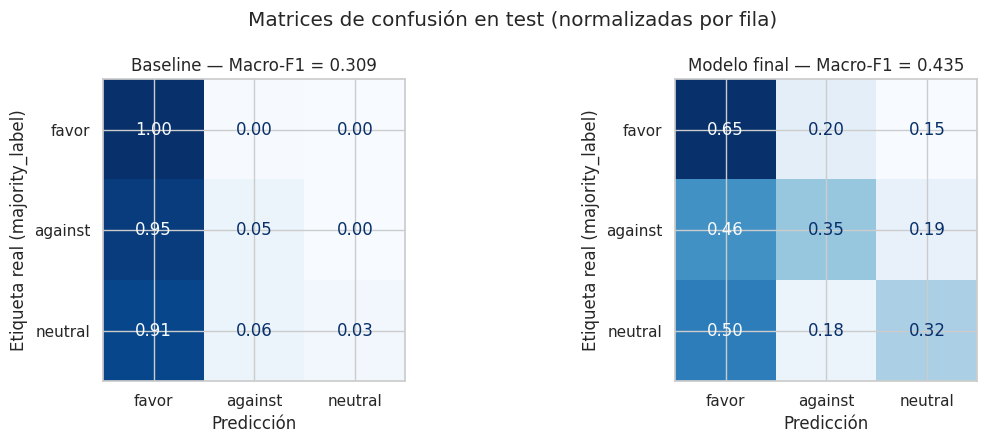

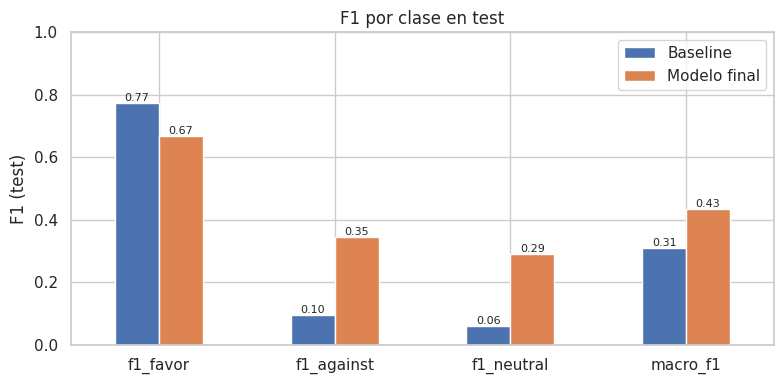

In [18]:
NOMBRE_BASE, NOMBRE_FINAL = list(res_test)[0], list(res_test)[-1]
_, pipe_final, y_pred_final = res_test[NOMBRE_FINAL]
_, pipe_base, y_pred_base = res_test[NOMBRE_BASE]

print("=== Modelo final (train+val) ===")
print(classification_report(y_test, y_pred_final, labels=CLASES, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (titulo, y_pred) in zip(axes, [("Baseline", y_pred_base), ("Modelo final", y_pred_final)]):
    cm = confusion_matrix(y_test, y_pred, labels=CLASES, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(f"{titulo} — Macro-F1 = {f1_score(y_test, y_pred, average='macro'):.3f}")
    ax.set_xlabel("Predicción"); ax.set_ylabel("Etiqueta real (majority_label)")
plt.suptitle("Matrices de confusión en test (normalizadas por fila)"); plt.tight_layout(); plt.show()

# F1 por clase: baseline vs. final
f1_clase = test_tabla.loc[[NOMBRE_BASE, NOMBRE_FINAL], [f"f1_{c}" for c in CLASES] + ["macro_f1"]]
f1_clase.index = ["Baseline", "Modelo final"]
ax = f1_clase.T.plot.bar(figsize=(8, 4), rot=0)
ax.set_ylabel("F1 (test)"); ax.set_title("F1 por clase en test"); ax.set_ylim(0, 1)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.show()

**Observaciones**

- Modelo final en test: Macro-F1 = 0,435 (accuracy 0,529), frente a 0,309 del baseline (+12,6 puntos). Reentrenar con train+val prácticamente no cambia el resultado (de 0,433 a 0,435).

- El resultado de test es menor que el de validación (0,493) y cercano al de la validación cruzada (0,456), lo que confirma que el puntaje de validación era optimista por el sesgo de selección. El baseline también cae entre validación y test (de 0,329 a 0,309), así que parte de la diferencia se debe a que el test es algo más difícil.
- La mejora viene de las clases minoritarias: F1 de *against* 0,10 a 0,35 y de *neutral* 0,06 a 0,29, a costa de *favor* (0,77 a 0,67) y de la accuracy (0,63 a 0,53).
- Confusiones: la mitad de los comentarios *neutral* (33 de 66) se predicen como *favor*, que es justamente la frontera más difusa entre anotadores en la parte 1. Casi la mitad de los *against* (44 de 95) también se predicen como *favor*. En sentido inverso, el 20% de los *favor* (51 de 257) se predicen como *against*.
- El desempeño sigue siendo bajo en términos absolutos. Ningún enfoque de bolsa de features superó ≈0,46 en validación cruzada, lo que sugiere un techo de los modelos clásicos para esta tarea.

### 2.10. Análisis del modelo final

#### 2.10.1. Desempeño según el acuerdo entre anotadores

Si el modelo falla sobre todo en los comentarios donde los anotadores tampoco coincidieron, parte del error se explica por la ambigüedad de las etiquetas (techo de desempeño discutido en la parte 1).

In [19]:
filas = []
for nivel in ["Total (3/3)", "Parcial (2/3)"]:
    m = (test_df["nivel_acuerdo"] == nivel).to_numpy()
    filas.append({"nivel_acuerdo": nivel, "n": m.sum(),
                  "accuracy": accuracy_score(y_test[m], y_pred_final[m]),
                  "macro_f1": f1_score(y_test[m], y_pred_final[m], labels=CLASES, average="macro", zero_division=0)})
display(pd.DataFrame(filas).set_index("nivel_acuerdo").round(3))

,n,accuracy,macro_f1
nivel_acuerdo,,,
Total (3/3),216,0.639,0.468
Parcial (2/3),202,0.411,0.377


#### 2.10.2. Términos más influyentes por clase

Para modelos lineales, los coeficientes indican qué features empujan la predicción hacia cada clase. Si el modelo final no es lineal, se usa la regresión logística con las mismas features para la interpretación.

In [20]:
pipe_interp = pipe_final
if not hasattr(pipe_final.named_steps["clf"], "coef_"):
    config_lr = dict(ELEGIDO["config"], modelo=LR_BAL)
    v, e = config_lr["variante"], config_lr["entrada"]
    pipe_interp = armar_pipeline(config_lr).fit(unir(armar_X("train", v, e), armar_X("val", v, e)),
                                                np.concatenate([y_train, y_val]))

nombres = pipe_interp.named_steps["feats"].get_feature_names_out()
clf = pipe_interp.named_steps["clf"]
top = {}
for i, clase in enumerate(clf.classes_):
    orden = np.argsort(clf.coef_[i])[::-1][:15]
    top[clase] = [f"{nombres[j]} ({clf.coef_[i][j]:.2f})" for j in orden]
display(pd.DataFrame(top)[CLASES])

,favor,against,neutral
0,rdo (0.55),no (0.85),é (0.62)
1,acue (0.51),no (0.83),1 (0.60)
2,acu (0.49),no (0.80),ué (0.60)
3,inc (0.49),no (0.76),inte (0.59)
4,otalm (0.47),eso (0.73),vota (0.56)
5,lida (0.47),qui (0.68),vota (0.56)
6,talme (0.47),eso (0.63),qué (0.56)
7,talm (0.47),tra (0.61),inte (0.52)
8,erdo (0.45),quie (0.59),4 (0.52)
9,mbi (0.43),eo (0.56),pero (0.51)


#### 2.10.3. Ejemplos de errores

In [21]:
errores = test_df.assign(pred=y_pred_final)[lambda d: d["pred"] != d["label"]]
print(f"Errores en test: {len(errores)} de {len(test_df)}\n")
for (real, pred), g in errores.groupby(["label", "pred"]):
    if len(g) < 5:
        continue
    print(f"=== Real: {real} | Predicho: {pred} ({len(g)} casos) ===")
    for _, fila in g.sample(min(2, len(g)), random_state=SEED).iterrows():
        print(f"• [{fila['target'][:60]}] {fila['comment'][:250]}")
        print(f"  Anotaciones: {fila[cols_anotadores].tolist()}\n")

Errores en test: 197 de 418

=== Real: against | Predicho: favor (44 casos) ===
• [Tambores en el Parque del Retiro en la tarde del domingo.] Creo que el parque del Retiro debe ser un refugio ante el ruido que nos rodea y acompaña todos los días. Creo que no se debía permitir ni tambores ni otros instrumentos. Tampoco entiendo porqué en cuando hay algún evento en el Retiro, ponen la música
  Anotaciones: ['against', 'against', 'favor']

• [Parar motores EMT cuando el conductor descansa?] Los buses se quedan encendidos por temas mecanicos. y para que al subir al autobus no tengas que pasar frio o calor  dependiendo de la epoca del año
  Anotaciones: ['against', 'against', 'favor']

=== Real: against | Predicho: neutral (18 casos) ===
• [Abolición del calendario festivo religioso ] Oigan esto no es un portal ni sitio de partido politicos como PODEMOS ni es un debate político. Lo digo porque he notado cierta obsesión e inquina por ese partido político y demás entonces busquense su lugar d

**Observaciones**

- El modelo funciona bastante mejor en comentarios con acuerdo total (Macro-F1 0,468, accuracy 0,64) que en los de acuerdo parcial (0,377, accuracy 0,41). Los errores se concentran en los casos que también resultaron ambiguos para los anotadores: parte del error no es "corregible" con la etiqueta mayoritaria como referencia.
- Los términos influyentes: los n-gramas de caracteres más importantes sí reflejan postura, no tema:
  - *favor*: fragmentos de *acuerdo*, *totalmente*, *apoyo*, *incluso*.
  - *against*: *no*, *eso*, *quiero*, *contra*.
  - *neutral*: signos y palabras de pregunta (*qué*, *por qué*), *vota/votar* y *pero*. Coincide con lo observado en la parte 1: muchos *neutral* son preguntas o comentarios sobre el proceso de votación más que sobre la propuesta.
  - Aparecen algunos dígitos (*1*, *4*) entre los términos de *neutral*, que probablemente sean asociaciones espurias del conjunto de entrenamiento.
- Los errores: en los ejemplos se repiten tres situaciones:
  - Comentarios con anotaciones divididas (2 a 1).
  - Comentarios cuya postura solo se entiende en relación con la propuesta: por ejemplo, explicar por qué los buses quedan encendidos es estar *en contra* de apagarlos, aunque no haya ninguna palabra negativa.
  - Comentarios que usan palabras "de favor" para expresar otra cosa: *"Estoy de acuerdo con la línea de argumentación…"* es *neutral*, y una crítica dura a una concejala es *favor* de su reprobación.

  Son los casos donde un modelo que entienda el contexto (partes 3 y 4) podría ayudar.

### 2.11. Guardado de resultados

Se grafica el Macro-F1 en validación de todos los experimentos y se guardan los resultados para la comparación entre enfoques (parte 5):
- `resultados_parte2_val.csv`: todos los experimentos sobre validación.

- `resultados_parte2_test.csv`: métricas, tiempos y tamaño en test del baseline y del modelo final.
- `predicciones_parte2_test.csv`: predicciones en test (para matrices de confusión y comparaciones por comentario entre enfoques).

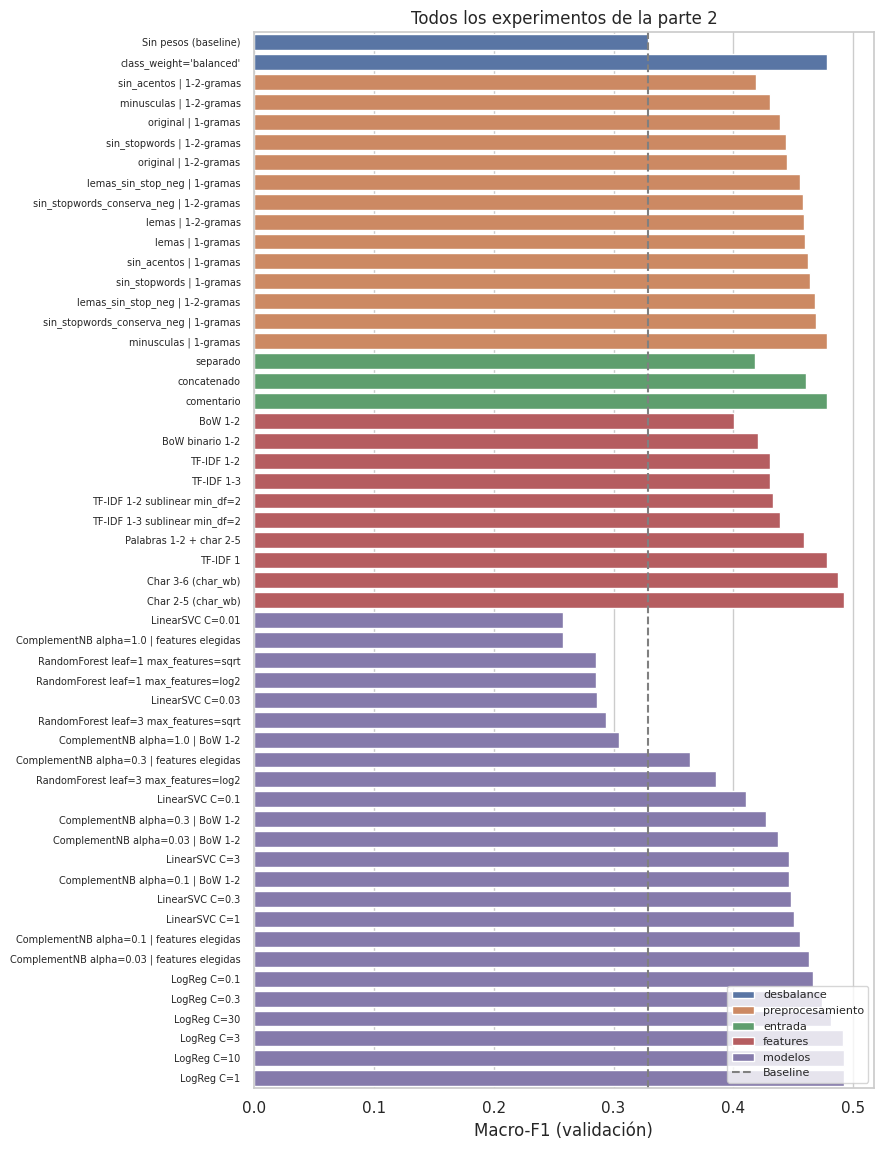

Archivos guardados.


In [22]:
res_val = pd.DataFrame(resultados)
res_val["config"] = res_val["config"].apply(
    lambda c: f"variante={c['variante']} | entrada={c['entrada']} | feats={c['cfg_feat']} | modelo={c['modelo']}")

grupos_orden = ["referencia", "desbalance", "preprocesamiento", "entrada", "features", "modelos"]
graf = res_val[res_val["grupo"] != "referencia"].copy()
graf = graf.sort_values(["grupo", "macro_f1"], key=lambda s: s.map(grupos_orden.index) if s.name == "grupo" else s)

fig, ax = plt.subplots(figsize=(9, max(6, len(graf) * 0.22)))
sns.barplot(data=graf, y="experimento", x="macro_f1", hue="grupo", dodge=False, ax=ax)
ax.axvline(BASELINE["macro_f1"], ls="--", c="gray", label="Baseline")
ax.set_xlabel("Macro-F1 (validación)"); ax.set_ylabel(""); ax.tick_params(axis="y", labelsize=7)
ax.set_title("Todos los experimentos de la parte 2"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

res_val.to_csv("resultados_parte2_val.csv", index=False)
test_tabla.assign(t_lematizacion_por_texto_ms=T_LEMATIZACION / len(todos) * 1000).to_csv("resultados_parte2_test.csv")
pd.DataFrame({"id": test_df["id"], "label": y_test,
              "pred_baseline": y_pred_base, "pred_final": y_pred_final}).to_csv("predicciones_parte2_test.csv", index=False)
print("Archivos guardados.")

### 2.12. Conclusiones de la etapa 2

- El Macro-F1 en test pasó de 0,309 (baseline) a 0,435 (TF-IDF de n-gramas de caracteres 2–5 + regresión logística balanceada, `C=1`). Casi toda la mejora viene del balanceo de clases (+15 puntos en validación). Cambiar a n-gramas de caracteres aporta ≈1,5 puntos más, dentro del margen de ruido.

- El preprocesamiento mínimo (minúsculas) fue el mejor. Eliminar stopwords, lematizar o quitar acentos no mejoró el resultado. La lematización, además, agrega ≈3,3 ms por texto. Conservar las negaciones es levemente mejor que eliminarlas.
- Agregar el título de la propuesta empeora el resultado. Los modelos de bolsa de palabras no pueden modelar la relación entre comentario y propuesta.
- Los modelos lineales (LogReg, SVM lineal, Complement NB) quedaron a menos de un desvío estándar entre sí en validación cruzada. Random Forest fue claramente peor y más lento. Los n-gramas de palabras más largos (bigramas, trigramas) no ayudaron con este tamaño de corpus.
- El modelo final se entrena en ≈3,7 s en CPU (2 núcleos de Colab, sin GPU), predice el test completo (418 comentarios) en ≈0,25 s (≈0,6 ms por comentario) y ocupa ≈1,3 MB. Es el punto de referencia de costo contra el cual comparar encoders y LLMs.
- Las limitaciones:
  - *neutral* sigue siendo la clase más difícil (F1 = 0,29 en test); la mitad se confunde con *favor*. Esto se debe en parte a la ambigüedad de las etiquetas: el desempeño cae de 0,47 a 0,38 de Macro-F1 en los comentarios con acuerdo parcial.
  - La búsqueda fue secuencial y con `C=1` fijo hasta el paso 2.8, por lo que representaciones más grandes (bigramas) pueden haber quedado en desventaja por no reajustar la regularización.
  - Los tiempos medidos en Colab son ruidosos: la misma configuración tardó entre 0,6 y 2,8 s en distintas corridas. Deben leerse como órdenes de magnitud.